# Home Loan Default – Risk Management

## Project Objective
To analyze customer loan application data and build machine learning models
that identify customers who are likely to default on their home loans.

## Project Goals
1. Perform Exploratory Data Analysis (EDA).
2. Understand customer and loan-related patterns.
3. Handle missing values and prepare data.
4. Perform feature engineering.
5. Build and compare multiple machine learning models.
6. Identify important factors associated with loan defaults.
7. Recommend the best-performing model.

In [4]:
import os
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Libraries imported successfully!
Pandas version: 2.3.3
NumPy version: 2.0.2


In [5]:
DATA_PATH = "../dataset/"

print("Dataset files:")

for file in os.listdir(DATA_PATH):
    print(file)

Dataset files:
POS_CASH_balance.csv
credit_card_balance.csv
installments_payments.csv
application_train.csv
bureau.csv
previous_application.csv
bureau_balance.csv


In [6]:
DATA_PATH = "../dataset/"

application_train = pd.read_csv(DATA_PATH + "application_train.csv")
bureau = pd.read_csv(DATA_PATH + "bureau.csv")
bureau_balance = pd.read_csv(DATA_PATH + "bureau_balance.csv")
pos_cash = pd.read_csv(DATA_PATH + "POS_CASH_balance.csv")
credit_card = pd.read_csv(DATA_PATH + "credit_card_balance.csv")
previous_application = pd.read_csv(DATA_PATH + "previous_application.csv")
installments = pd.read_csv(DATA_PATH + "installments_payments.csv")

print("All seven datasets loaded successfully!")

All seven datasets loaded successfully!


In [7]:
datasets = {
    "Application Train": application_train,
    "Bureau": bureau,
    "Bureau Balance": bureau_balance,
    "POS Cash": pos_cash,
    "Credit Card": credit_card,
    "Previous Application": previous_application,
    "Installments": installments
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])


Application Train
Rows: 307511
Columns: 122

Bureau
Rows: 1716428
Columns: 17

Bureau Balance
Rows: 27299925
Columns: 3

POS Cash
Rows: 10001358
Columns: 8

Credit Card
Rows: 3840312
Columns: 23

Previous Application
Rows: 1670214
Columns: 37

Installments
Rows: 13605401
Columns: 8


In [8]:
print(application_train["TARGET"].value_counts())

print("\nTarget percentage:")
print(application_train["TARGET"].value_counts(normalize=True) * 100)

TARGET
0    282686
1     24825
Name: count, dtype: int64

Target percentage:
TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


In [9]:
target_counts = application_train["TARGET"].value_counts()

print("Target distribution:")
print(target_counts)

print("\nTarget percentage:")
print((application_train["TARGET"].value_counts(normalize=True) * 100).round(2))

Target distribution:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Target percentage:
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


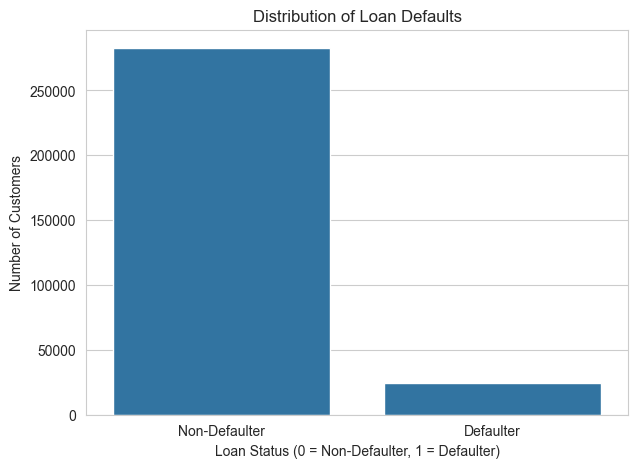

In [10]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=application_train,
    x="TARGET"
)

plt.title("Distribution of Loan Defaults")
plt.xlabel("Loan Status (0 = Non-Defaulter, 1 = Defaulter)")
plt.ylabel("Number of Customers")
plt.xticks([0, 1], ["Non-Defaulter", "Defaulter"])

plt.show()

Step 10 — Understand the main dataset

In [11]:
application_train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [12]:
print("Total columns:", len(application_train.columns))

for column in application_train.columns:
    print(column)

Total columns: 122
SK_ID_CURR
TARGET
NAME_CONTRACT_TYPE
CODE_GENDER
FLAG_OWN_CAR
FLAG_OWN_REALTY
CNT_CHILDREN
AMT_INCOME_TOTAL
AMT_CREDIT
AMT_ANNUITY
AMT_GOODS_PRICE
NAME_TYPE_SUITE
NAME_INCOME_TYPE
NAME_EDUCATION_TYPE
NAME_FAMILY_STATUS
NAME_HOUSING_TYPE
REGION_POPULATION_RELATIVE
DAYS_BIRTH
DAYS_EMPLOYED
DAYS_REGISTRATION
DAYS_ID_PUBLISH
OWN_CAR_AGE
FLAG_MOBIL
FLAG_EMP_PHONE
FLAG_WORK_PHONE
FLAG_CONT_MOBILE
FLAG_PHONE
FLAG_EMAIL
OCCUPATION_TYPE
CNT_FAM_MEMBERS
REGION_RATING_CLIENT
REGION_RATING_CLIENT_W_CITY
WEEKDAY_APPR_PROCESS_START
HOUR_APPR_PROCESS_START
REG_REGION_NOT_LIVE_REGION
REG_REGION_NOT_WORK_REGION
LIVE_REGION_NOT_WORK_REGION
REG_CITY_NOT_LIVE_CITY
REG_CITY_NOT_WORK_CITY
LIVE_CITY_NOT_WORK_CITY
ORGANIZATION_TYPE
EXT_SOURCE_1
EXT_SOURCE_2
EXT_SOURCE_3
APARTMENTS_AVG
BASEMENTAREA_AVG
YEARS_BEGINEXPLUATATION_AVG
YEARS_BUILD_AVG
COMMONAREA_AVG
ELEVATORS_AVG
ENTRANCES_AVG
FLOORSMAX_AVG
FLOORSMIN_AVG
LANDAREA_AVG
LIVINGAPARTMENTS_AVG
LIVINGAREA_AVG
NONLIVINGAPARTMENTS_AVG
NONL

In [13]:
application_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


In [14]:
application_train.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,100002.0,189145.5,278202.0,367142.5,456255.0
TARGET,307511.0,0.080729,0.272419,0.0,0.0,0.0,0.0,1.0
CNT_CHILDREN,307511.0,0.417052,0.722121,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,270000.0,513531.0,808650.0,4050000.0
...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,265992.0,0.007000,0.110757,0.0,0.0,0.0,0.0,9.0
AMT_REQ_CREDIT_BUREAU_WEEK,265992.0,0.034362,0.204685,0.0,0.0,0.0,0.0,8.0
AMT_REQ_CREDIT_BUREAU_MON,265992.0,0.267395,0.916002,0.0,0.0,0.0,0.0,27.0
AMT_REQ_CREDIT_BUREAU_QRT,265992.0,0.265474,0.794056,0.0,0.0,0.0,0.0,261.0


In [15]:
missing_values = pd.DataFrame({
    "Missing_Count": application_train.isnull().sum(),
    "Missing_Percentage": (
        application_train.isnull().sum() / len(application_train)
    ) * 100
})

missing_values = missing_values[
    missing_values["Missing_Count"] > 0
].sort_values(
    by="Missing_Percentage",
    ascending=False
)

missing_values.head(20)

,Missing_Count,Missing_Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_MODE,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953
LIVINGAPARTMENTS_AVG,210199,68.354953


Step 11 — Investigate missing values properly

In [16]:
missing_summary = pd.DataFrame({
    "Column": application_train.columns,
    "Data_Type": application_train.dtypes.values,
    "Missing_Count": application_train.isnull().sum().values,
    "Missing_Percentage": (
        application_train.isnull().sum().values /
        len(application_train)
    ) * 100
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values(
    by="Missing_Percentage",
    ascending=False
)

missing_summary

,Column,Data_Type,Missing_Count,Missing_Percentage
76,COMMONAREA_MEDI,float64,214865,69.872297
48,COMMONAREA_AVG,float64,214865,69.872297
62,COMMONAREA_MODE,float64,214865,69.872297
84,NONLIVINGAPARTMENTS_MEDI,float64,213514,69.432963
70,NONLIVINGAPARTMENTS_MODE,float64,213514,69.432963
...,...,...,...,...
42,EXT_SOURCE_2,float64,660,0.214626
10,AMT_GOODS_PRICE,float64,278,0.090403
9,AMT_ANNUITY,float64,12,0.003902
29,CNT_FAM_MEMBERS,float64,2,0.000650


In [17]:
print("Missing values in numerical columns:",
      application_train.select_dtypes(include=np.number).isnull().sum().sum())

print("Missing values in categorical columns:",
      application_train.select_dtypes(include="object").isnull().sum().sum())

Missing values in numerical columns: 8388094
Missing values in categorical columns: 764371


In [18]:
print("Total duplicate rows:",
      application_train.duplicated().sum())

print("Duplicate customer IDs:",
      application_train["SK_ID_CURR"].duplicated().sum())

Total duplicate rows: 0
Duplicate customer IDs: 0


In [19]:
categorical_columns = application_train.select_dtypes(
    include="object"
).columns

print("Total categorical columns:", len(categorical_columns))

for column in categorical_columns[:10]:
    print("\nColumn:", column)
    print(application_train[column].value_counts(dropna=False).head(10))

Total categorical columns: 16

Column: NAME_CONTRACT_TYPE
NAME_CONTRACT_TYPE
Cash loans         278232
Revolving loans     29279
Name: count, dtype: int64

Column: CODE_GENDER
CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64

Column: FLAG_OWN_CAR
FLAG_OWN_CAR
N    202924
Y    104587
Name: count, dtype: int64

Column: FLAG_OWN_REALTY
FLAG_OWN_REALTY
Y    213312
N     94199
Name: count, dtype: int64

Column: NAME_TYPE_SUITE
NAME_TYPE_SUITE
Unaccompanied      248526
Family              40149
Spouse, partner     11370
Children             3267
Other_B              1770
NaN                  1292
Other_A               866
Group of people       271
Name: count, dtype: int64

Column: NAME_INCOME_TYPE
NAME_INCOME_TYPE
Working                 158774
Commercial associate     71617
Pensioner                55362
State servant            21703
Unemployed                  22
Student                     18
Businessman                 10
Maternity leave              5
Na

Step 12 — Understand which customer features are associated with loan default

In [20]:
contract_default = application_train.groupby(
    "NAME_CONTRACT_TYPE"
)["TARGET"].mean() * 100

print(contract_default.round(2))

NAME_CONTRACT_TYPE
Cash loans         8.35
Revolving loans    5.48
Name: TARGET, dtype: float64


In [21]:
education_default = (
    application_train.groupby("NAME_EDUCATION_TYPE")["TARGET"]
    .mean() * 100
)

print(education_default.sort_values(ascending=False).round(2))

NAME_EDUCATION_TYPE
Lower secondary                  10.93
Secondary / secondary special     8.94
Incomplete higher                 8.48
Higher education                  5.36
Academic degree                   1.83
Name: TARGET, dtype: float64


In [22]:
income_default = (
    application_train.groupby("NAME_INCOME_TYPE")["TARGET"]
    .mean() * 100
)

print(income_default.sort_values(ascending=False).round(2))

NAME_INCOME_TYPE
Maternity leave         40.00
Unemployed              36.36
Working                  9.59
Commercial associate     7.48
State servant            5.75
Pensioner                5.39
Businessman              0.00
Student                  0.00
Name: TARGET, dtype: float64


In [23]:
income_comparison = application_train.groupby(
    "TARGET"
)["AMT_INCOME_TOTAL"].agg(
    ["mean", "median", "min", "max"]
)

income_comparison.index = [
    "Non-Defaulters",
    "Defaulters"
]

income_comparison

,mean,median,min,max
Non-Defaulters,169077.722266,148500.0,25650.0,18000090.0
Defaulters,165611.760906,135000.0,25650.0,117000000.0


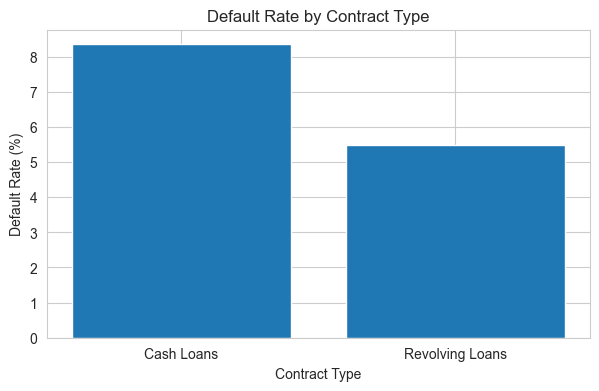

In [24]:
plt.figure(figsize=(7, 4))

plt.bar(
    ["Cash Loans", "Revolving Loans"],
    [8.35, 5.48]
)

plt.title("Default Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Default Rate (%)")

plt.show()

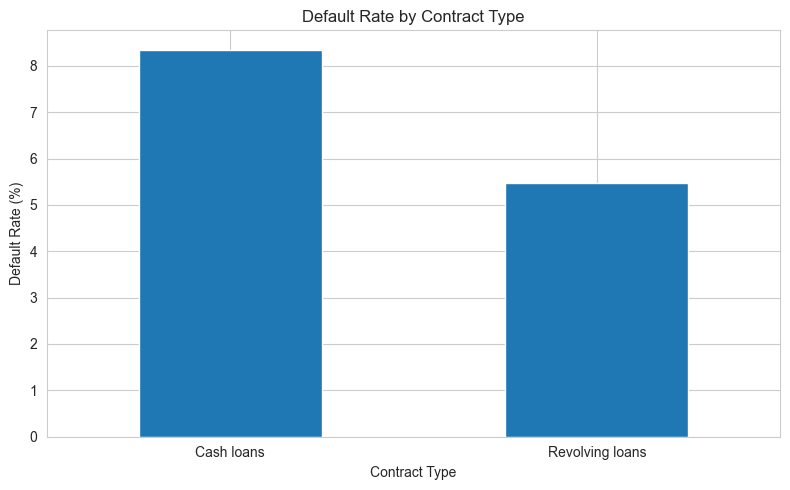

In [25]:
plt.figure(figsize=(8, 5))
contract_default.plot(kind="bar")

plt.title("Default Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

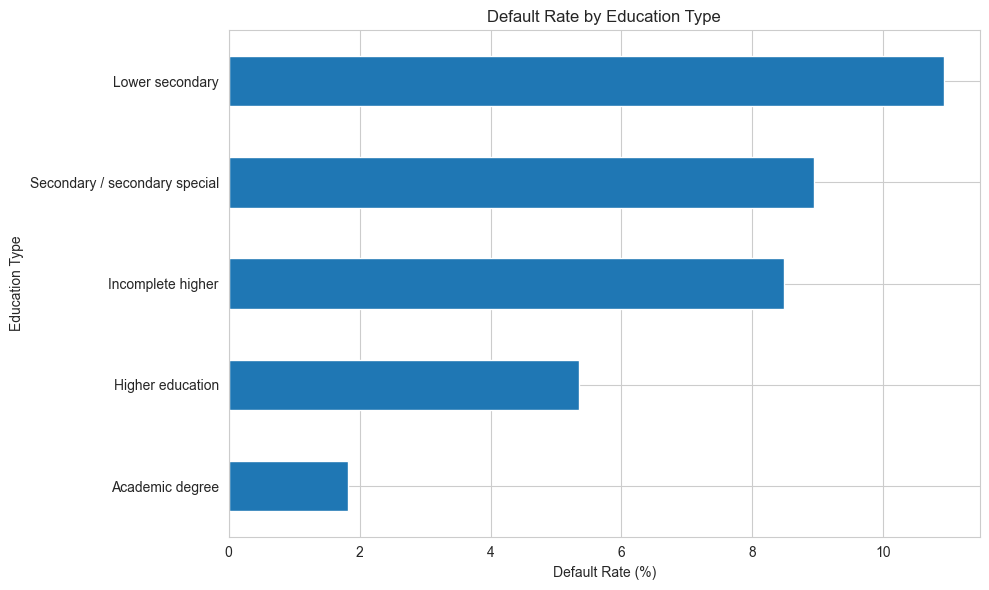

In [26]:
plt.figure(figsize=(10, 6))
education_default.sort_values().plot(kind="barh")

plt.title("Default Rate by Education Type")
plt.xlabel("Default Rate (%)")
plt.ylabel("Education Type")
plt.tight_layout()
plt.show()

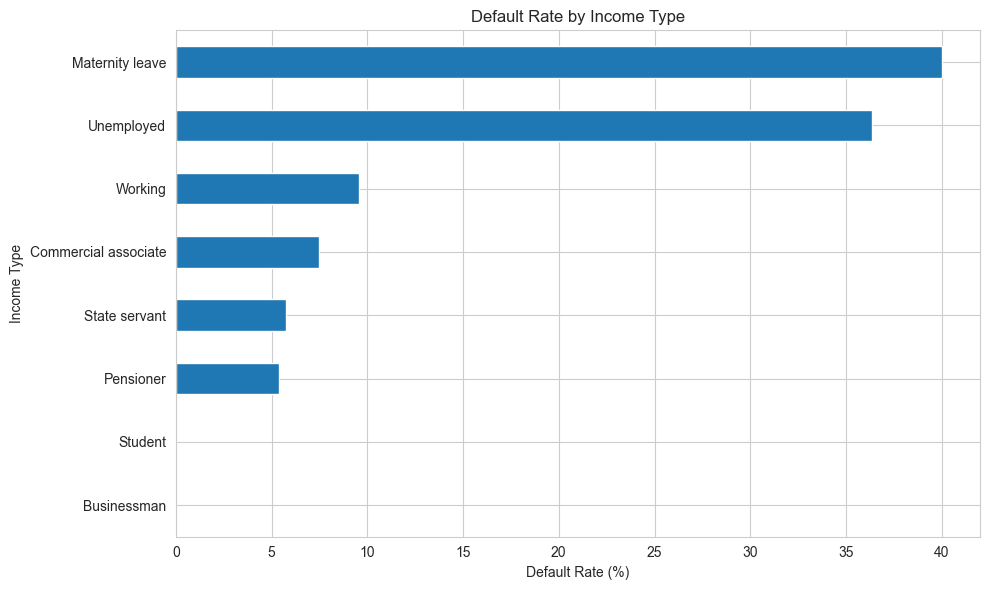

In [27]:
plt.figure(figsize=(10, 6))
income_default.sort_values().plot(kind="barh")

plt.title("Default Rate by Income Type")
plt.xlabel("Default Rate (%)")
plt.ylabel("Income Type")
plt.tight_layout()
plt.show()

<Figure size 800x500 with 0 Axes>

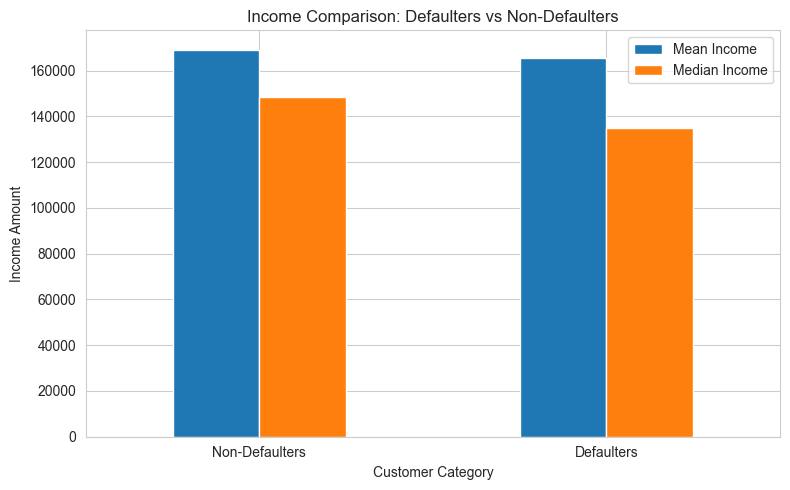

In [28]:
plt.figure(figsize=(8, 5))

income_comparison[["mean", "median"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Income Comparison: Defaulters vs Non-Defaulters")
plt.xlabel("Customer Category")
plt.ylabel("Income Amount")
plt.xticks(rotation=0)
plt.legend(["Mean Income", "Median Income"])
plt.tight_layout()
plt.show()

In [29]:
income_group_analysis = application_train.groupby(
    "NAME_INCOME_TYPE"
).agg(
    Total_Customers=("TARGET", "count"),
    Defaulters=("TARGET", "sum"),
    Default_Rate=("TARGET", "mean")
)

income_group_analysis["Default_Rate"] *= 100

income_group_analysis.sort_values(
    by="Default_Rate",
    ascending=False
).round(2)

,Total_Customers,Defaulters,Default_Rate
NAME_INCOME_TYPE,,,
Maternity leave,5,2,40.00
Unemployed,22,8,36.36
Working,158774,15224,9.59
Commercial associate,71617,5360,7.48
State servant,21703,1249,5.75
Pensioner,55362,2982,5.39
Businessman,10,0,0.00
Student,18,0,0.00


Step 13 — Numerical feature analysis

In [30]:
application_train["AGE_YEARS"] = (
    -application_train["DAYS_BIRTH"] / 365.25
)

application_train["AGE_YEARS"].describe()

count    307511.000000
mean         43.906900
std          11.947950
min          20.503765
25%          33.984942
50%          43.121150
75%          53.886379
max          69.073238
Name: AGE_YEARS, dtype: float64

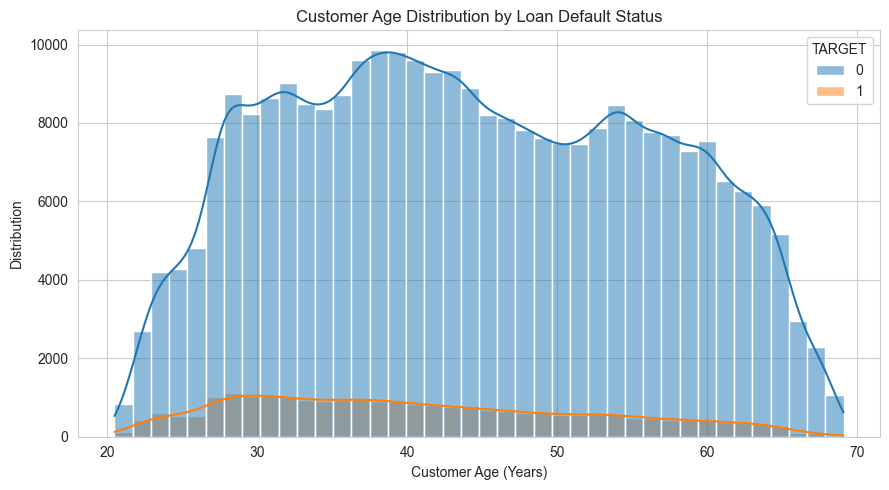

In [31]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=application_train,
    x="AGE_YEARS",
    hue="TARGET",
    bins=40,
    kde=True,
    common_norm=False
)

plt.title("Customer Age Distribution by Loan Default Status")
plt.xlabel("Customer Age (Years)")
plt.ylabel("Distribution")
plt.tight_layout()
plt.show()

In [32]:
application_train["AGE_GROUP"] = pd.cut(
    application_train["AGE_YEARS"],
    bins=[20, 30, 40, 50, 60, 70, 100],
    labels=[
        "20-30",
        "30-40",
        "40-50",
        "50-60",
        "60-70",
        "70+"
    ],
    right=False
)

age_default = application_train.groupby(
    "AGE_GROUP",
    observed=False
).agg(
    Total_Customers=("TARGET", "count"),
    Defaulters=("TARGET", "sum"),
    Default_Rate=("TARGET", "mean")
)

age_default["Default_Rate"] *= 100

age_default.round(2)

,Total_Customers,Defaulters,Default_Rate
AGE_GROUP,,,
20-30,45186,5171,11.44
30-40,82331,7897,9.59
40-50,76599,5853,7.64
50-60,68094,4168,6.12
60-70,35301,1736,4.92
70+,0,0,NaN


In [33]:
application_train["CREDIT_INCOME_RATIO"] = (
    application_train["AMT_CREDIT"] /
    application_train["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

application_train["CREDIT_INCOME_RATIO"].describe()

count    307511.000000
mean          3.957570
std           2.689728
min           0.004808
25%           2.018667
50%           3.265067
75%           5.159880
max          84.736842
Name: CREDIT_INCOME_RATIO, dtype: float64

In [34]:
ratio_comparison = application_train.groupby(
    "TARGET"
)["CREDIT_INCOME_RATIO"].agg(
    ["mean", "median"]
)

ratio_comparison.index = [
    "Non-Defaulters",
    "Defaulters"
]

ratio_comparison

,mean,median
Non-Defaulters,3.963729,3.266653
Defaulters,3.887438,3.253143


Step 14 — Analyze employment experience

In [35]:
print("Employment days summary:")
print(application_train["DAYS_EMPLOYED"].describe())

print("\nMost common employment values:")
print(application_train["DAYS_EMPLOYED"].value_counts().head(10))

print("\nSpecial value count:")
print((application_train["DAYS_EMPLOYED"] == 365243).sum())

Employment days summary:
count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

Most common employment values:
DAYS_EMPLOYED
 365243    55374
-200         156
-224         152
-230         151
-199         151
-212         150
-384         143
-229         143
-231         140
-215         138
Name: count, dtype: int64

Special value count:
55374


In [36]:
application_train["EMPLOYMENT_YEARS"] = (
    -application_train["DAYS_EMPLOYED"].replace(
        365243, np.nan
    ) / 365.25
)

application_train["EMPLOYMENT_YEARS"].describe()

count    252137.000000
mean          6.527500
std           6.402081
min          -0.000000
25%           2.099932
50%           4.511978
75%           8.692676
max          49.040383
Name: EMPLOYMENT_YEARS, dtype: float64

In [37]:
employment_comparison = application_train.groupby(
    "TARGET"
)["EMPLOYMENT_YEARS"].agg(
    ["count", "mean", "median"]
)

employment_comparison.index = [
    "Non-Defaulters",
    "Defaulters"
]

employment_comparison.round(2)

,count,mean,median
Non-Defaulters,230302,6.68,4.63
Defaulters,21835,4.97,3.37


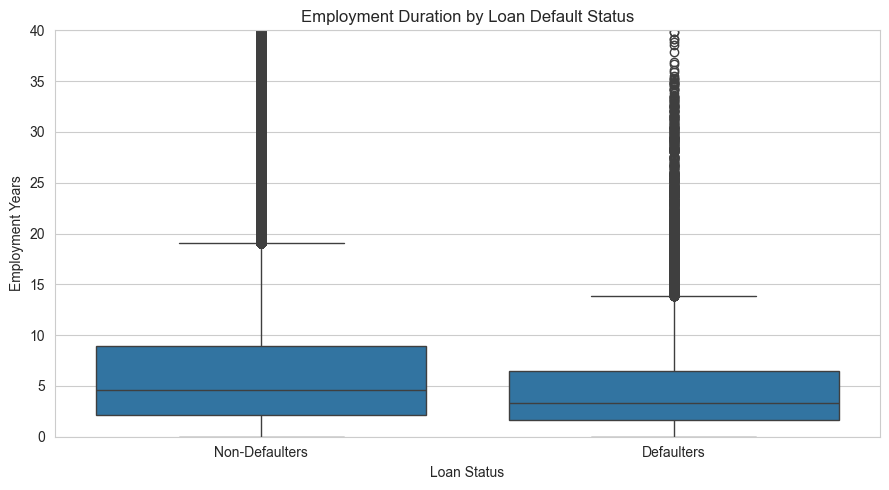

In [38]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=application_train,
    x="TARGET",
    y="EMPLOYMENT_YEARS"
)

plt.ylim(0, 40)

plt.title("Employment Duration by Loan Default Status")
plt.xlabel("Loan Status")
plt.ylabel("Employment Years")
plt.xticks([0, 1], ["Non-Defaulters", "Defaulters"])

plt.tight_layout()
plt.show()

Step 15 – Analyse financial repayment burden

In [39]:
# Annuity amount compared with total income
application_train["ANNUITY_INCOME_RATIO"] = (
    application_train["AMT_ANNUITY"] /
    application_train["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

# Goods price compared with credit amount
application_train["GOODS_CREDIT_RATIO"] = (
    application_train["AMT_GOODS_PRICE"] /
    application_train["AMT_CREDIT"].replace(0, np.nan)
)

print("Annuity-to-Income Ratio:")
display(application_train["ANNUITY_INCOME_RATIO"].describe())

print("\nGoods-Price-to-Credit Ratio:")
display(application_train["GOODS_CREDIT_RATIO"].describe())

Annuity-to-Income Ratio:


count    307499.000000
mean          0.180930
std           0.094574
min           0.000224
25%           0.114782
50%           0.162833
75%           0.229067
max           1.875965
Name: ANNUITY_INCOME_RATIO, dtype: float64


Goods-Price-to-Credit Ratio:


count    307233.000000
mean          0.900689
std           0.096630
min           0.166667
25%           0.834725
50%           0.893815
75%           1.000000
max           6.666667
Name: GOODS_CREDIT_RATIO, dtype: float64

In [40]:
financial_comparison = application_train.groupby("TARGET").agg(
    ANNUITY_INCOME_MEAN=("ANNUITY_INCOME_RATIO", "mean"),
    ANNUITY_INCOME_MEDIAN=("ANNUITY_INCOME_RATIO", "median"),
    GOODS_CREDIT_MEAN=("GOODS_CREDIT_RATIO", "mean"),
    GOODS_CREDIT_MEDIAN=("GOODS_CREDIT_RATIO", "median")
)

financial_comparison.index = [
    "Non-Defaulters",
    "Defaulters"
]

display(financial_comparison.round(3))

,ANNUITY_INCOME_MEAN,ANNUITY_INCOME_MEDIAN,GOODS_CREDIT_MEAN,GOODS_CREDIT_MEDIAN
Non-Defaulters,0.181,0.162,0.903,0.894
Defaulters,0.185,0.169,0.879,0.873


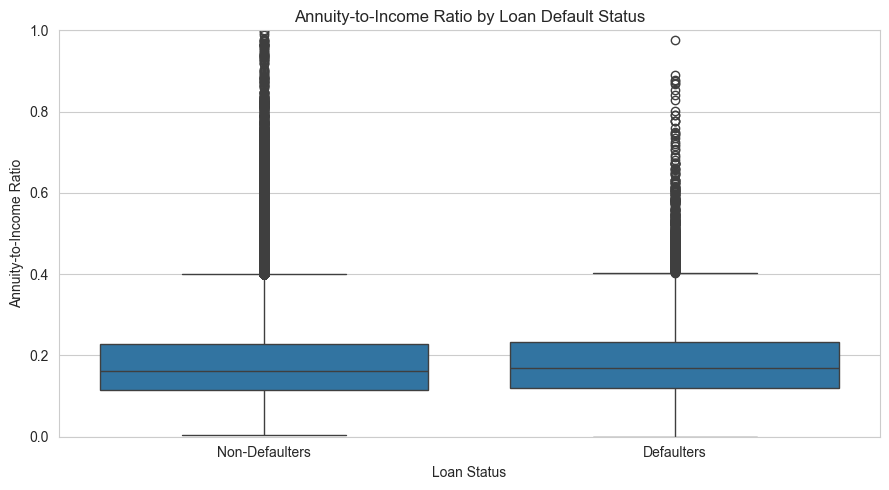

In [41]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=application_train,
    x="TARGET",
    y="ANNUITY_INCOME_RATIO"
)

plt.ylim(0, 1)
plt.title("Annuity-to-Income Ratio by Loan Default Status")
plt.xlabel("Loan Status")
plt.ylabel("Annuity-to-Income Ratio")
plt.xticks([0, 1], ["Non-Defaulters", "Defaulters"])

plt.tight_layout()
plt.show()

Step 16 – Identify potential outliers

In [42]:
financial_columns = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "CREDIT_INCOME_RATIO",
    "ANNUITY_INCOME_RATIO",
    "GOODS_CREDIT_RATIO"
]

financial_summary = application_train[financial_columns].describe(
    percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
).T

display(financial_summary.round(2))

,count,mean,std,min,1%,5%,50%,95%,99%,max
AMT_INCOME_TOTAL,307511.0,168797.92,237123.15,25650.00,45000.00,67500.00,147150.00,337500.00,472500.00,1.170000e+08
AMT_CREDIT,307511.0,599026.00,402490.78,45000.00,76410.00,135000.00,513531.00,1350000.00,1854000.00,4.050000e+06
AMT_ANNUITY,307499.0,27108.57,14493.74,1615.50,6182.91,9000.00,24903.00,53325.00,70006.50,2.580255e+05
AMT_GOODS_PRICE,307233.0,538396.21,369446.46,40500.00,67500.00,135000.00,450000.00,1305000.00,1800000.00,4.050000e+06
CREDIT_INCOME_RATIO,307511.0,3.96,2.69,0.00,0.60,1.00,3.27,9.16,13.03,8.474000e+01
ANNUITY_INCOME_RATIO,307499.0,0.18,0.09,0.00,0.04,0.06,0.16,0.35,0.48,1.880000e+00
GOODS_CREDIT_RATIO,307233.0,0.90,0.10,0.17,0.68,0.72,0.89,1.00,1.00,6.670000e+00


In [43]:
outlier_summary = []

for column in financial_columns:

    Q1 = application_train[column].quantile(0.25)
    Q3 = application_train[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = application_train[
        (application_train[column] < lower_limit) |
        (application_train[column] > upper_limit)
    ][column].count()

    outlier_summary.append({
        "Feature": column,
        "Lower_Limit": lower_limit,
        "Upper_Limit": upper_limit,
        "Potential_Outliers": outliers,
        "Outlier_Percentage": (
            outliers / len(application_train)
        ) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary.round(2))

,Feature,Lower_Limit,Upper_Limit,Potential_Outliers,Outlier_Percentage
0,AMT_INCOME_TOTAL,-22500.00,337500.00,14035,4.56
1,AMT_CREDIT,-537975.00,1616625.00,6562,2.13
2,AMT_ANNUITY,-10584.00,61704.00,7504,2.44
3,AMT_GOODS_PRICE,-423000.00,1341000.00,14728,4.79
4,CREDIT_INCOME_RATIO,-2.69,9.87,11510,3.74
5,ANNUITY_INCOME_RATIO,-0.06,0.40,7878,2.56
6,GOODS_CREDIT_RATIO,0.59,1.25,244,0.08


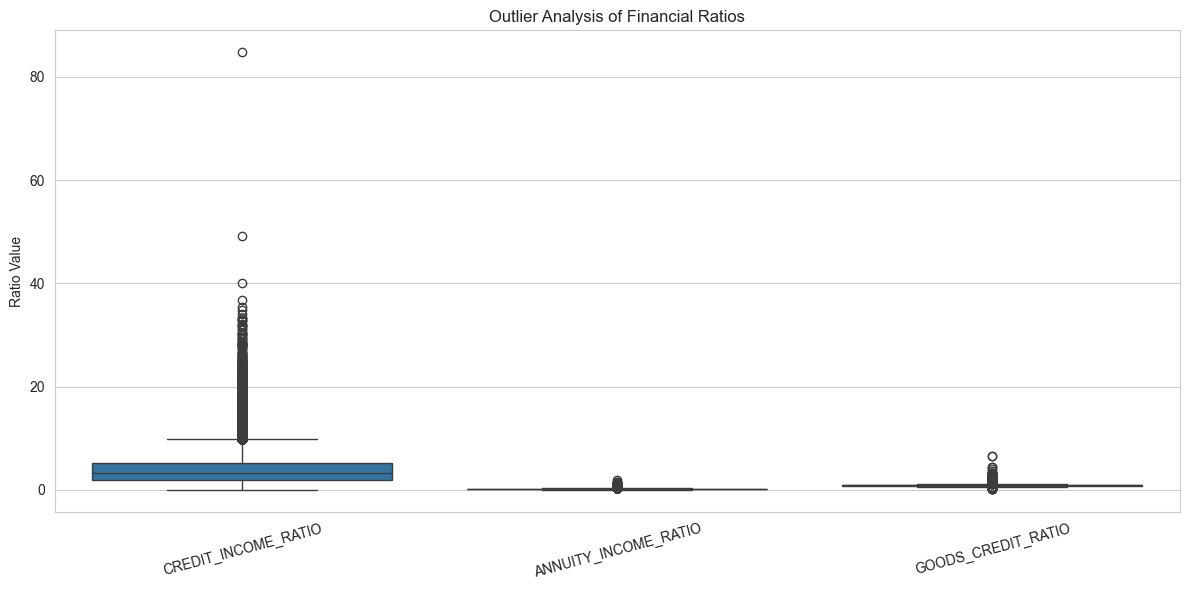

In [44]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=application_train[
        ["CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO",
         "GOODS_CREDIT_RATIO"]
    ]
)

plt.title("Outlier Analysis of Financial Ratios")
plt.ylabel("Ratio Value")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [45]:
# Display 15 customers with the highest income
high_income = application_train.nlargest(
    15, "AMT_INCOME_TOTAL"
)[[
    "SK_ID_CURR",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "TARGET"
]]

display(high_income)

,SK_ID_CURR,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,TARGET
12840,114967,117000000.0,562491.0,26194.5,1
203693,336147,18000090.0,675000.0,69295.5,0
246858,385674,13500000.0,1400503.5,130945.5,0
77768,190160,9000000.0,1431531.0,132601.5,0
131127,252084,6750000.0,790830.0,52978.5,0
103006,219563,4500000.0,2250000.0,225000.0,0
187833,317748,4500000.0,835380.0,42651.0,0
204564,337151,4500000.0,450000.0,47749.5,0
287463,432980,4500000.0,1755000.0,61132.5,0
181698,310601,3950059.5,675000.0,66217.5,0


In [46]:
# Customers with the highest credit-to-income ratios
high_ratio = application_train.nlargest(
    15, "CREDIT_INCOME_RATIO"
)[[
    "SK_ID_CURR",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "CREDIT_INCOME_RATIO",
    "TARGET"
]]

display(high_ratio)

,SK_ID_CURR,AMT_INCOME_TOTAL,AMT_CREDIT,CREDIT_INCOME_RATIO,TARGET
20727,124157,25650.0,2173500.0,84.736842,1
35791,141454,45000.0,2215224.0,49.227200,0
226137,361920,45000.0,1800000.0,40.000000,1
255247,395348,58500.0,2146500.0,36.692308,1
158077,283247,40500.0,1436850.0,35.477778,0
678,100784,54000.0,1885500.0,34.916667,1
205575,338291,36000.0,1223010.0,33.972500,1
103862,220543,54000.0,1800000.0,33.333333,0
165555,291918,27000.0,900000.0,33.333333,0
193574,324475,27900.0,916470.0,32.848387,0


In [47]:
amount_columns = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE"
]

for column in amount_columns:
    print(
        column,
        "| Zero values:", (application_train[column] == 0).sum(),
        "| Negative values:", (application_train[column] < 0).sum()
    )

AMT_INCOME_TOTAL | Zero values: 0 | Negative values: 0
AMT_CREDIT | Zero values: 0 | Negative values: 0
AMT_ANNUITY | Zero values: 0 | Negative values: 0
AMT_GOODS_PRICE | Zero values: 0 | Negative values: 0


Step 17 – Check skewness in numerical features

In [50]:
skew_columns = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "CREDIT_INCOME_RATIO",
    "ANNUITY_INCOME_RATIO",
    "GOODS_CREDIT_RATIO",
    "AGE_YEARS",
    "EMPLOYMENT_YEARS"
]

skewness_summary = pd.DataFrame({
    "Feature": skew_columns,
    "Skewness": [
        application_train[column].skew()
        for column in skew_columns
    ]
})

skewness_summary["Skewness_Type"] = skewness_summary[
    "Skewness"
].apply(
    lambda x: (
        "Highly Positive" if x > 1
        else "Highly Negative" if x < -1
        else "Approximately Symmetric"
    )
)

display(skewness_summary.round(3))

,Feature,Skewness,Skewness_Type
0,AMT_INCOME_TOTAL,391.560,Highly Positive
1,AMT_CREDIT,1.235,Highly Positive
2,AMT_ANNUITY,1.580,Highly Positive
3,AMT_GOODS_PRICE,1.349,Highly Positive
4,CREDIT_INCOME_RATIO,1.836,Highly Positive
5,ANNUITY_INCOME_RATIO,1.512,Highly Positive
6,GOODS_CREDIT_RATIO,2.667,Highly Positive
7,AGE_YEARS,0.116,Approximately Symmetric
8,EMPLOYMENT_YEARS,1.968,Highly Positive


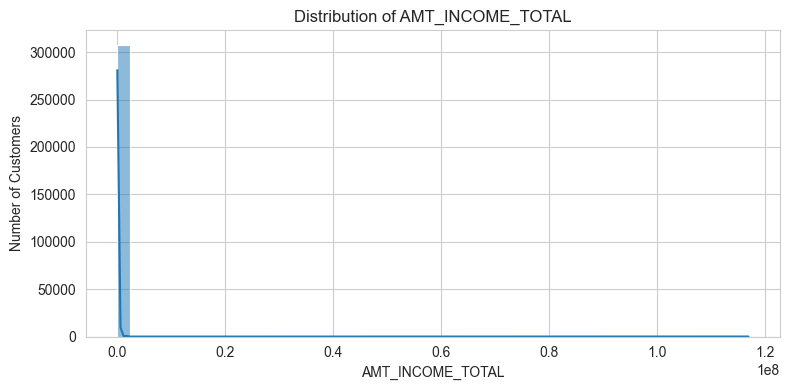

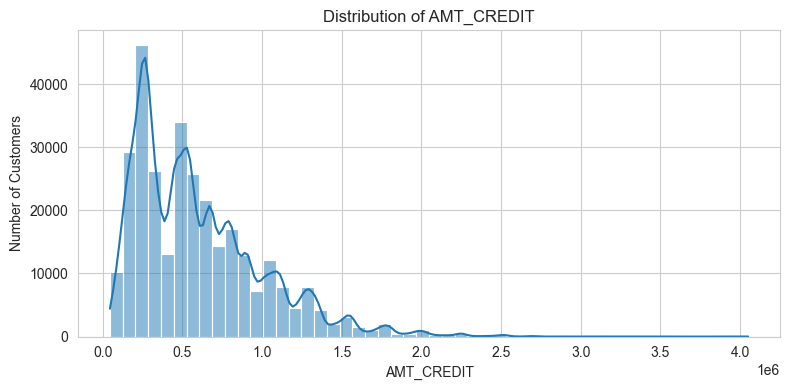

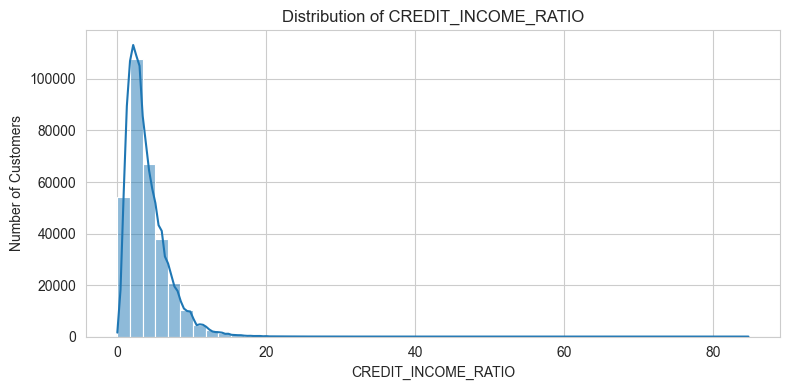

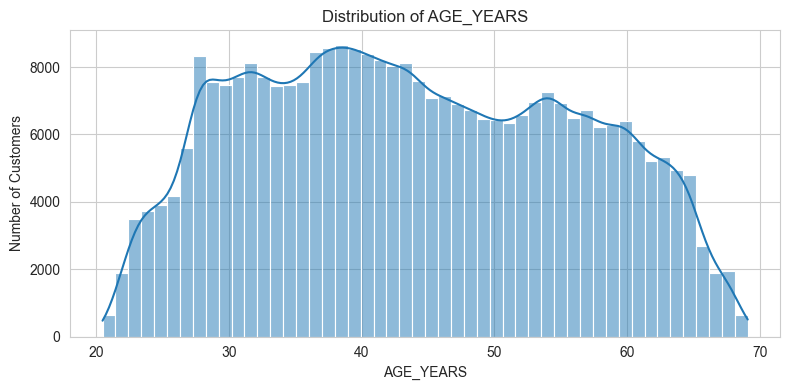

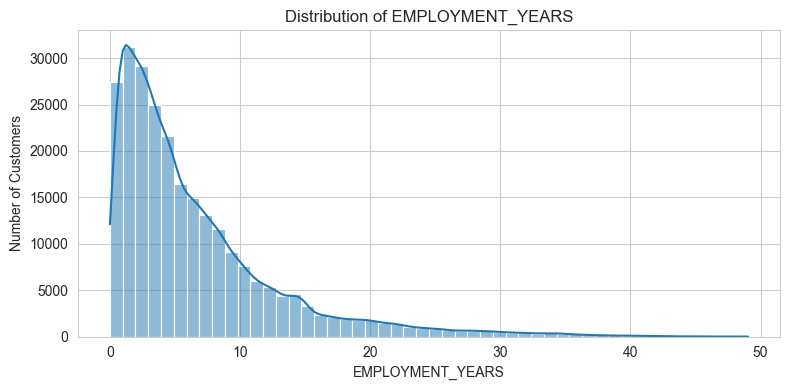

In [51]:
plot_columns = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "CREDIT_INCOME_RATIO",
    "AGE_YEARS",
    "EMPLOYMENT_YEARS"
]

for column in plot_columns:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=application_train,
        x=column,
        bins=50,
        kde=True
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of Customers")

    plt.tight_layout()
    plt.show()

Step 18 – Correlation analysis with loan default

In [52]:
# Select numerical columns
numeric_data = application_train.select_dtypes(
    include=["int64", "float64"]
)

# Calculate correlation with TARGET
target_correlation = numeric_data.corr()["TARGET"].drop(
    "TARGET"
)

# Sort by absolute correlation
target_correlation = target_correlation.reindex(
    target_correlation.abs().sort_values(
        ascending=False
    ).index
)

display(target_correlation.head(20).to_frame(
    name="Correlation_with_TARGET"
).round(4))

,Correlation_with_TARGET
EXT_SOURCE_3,-0.1789
EXT_SOURCE_2,-0.1605
EXT_SOURCE_1,-0.1553
AGE_YEARS,-0.0782
DAYS_BIRTH,0.0782
EMPLOYMENT_YEARS,-0.0750
GOODS_CREDIT_RATIO,-0.0654
REGION_RATING_CLIENT_W_CITY,0.0609
REGION_RATING_CLIENT,0.0589
DAYS_LAST_PHONE_CHANGE,0.0552


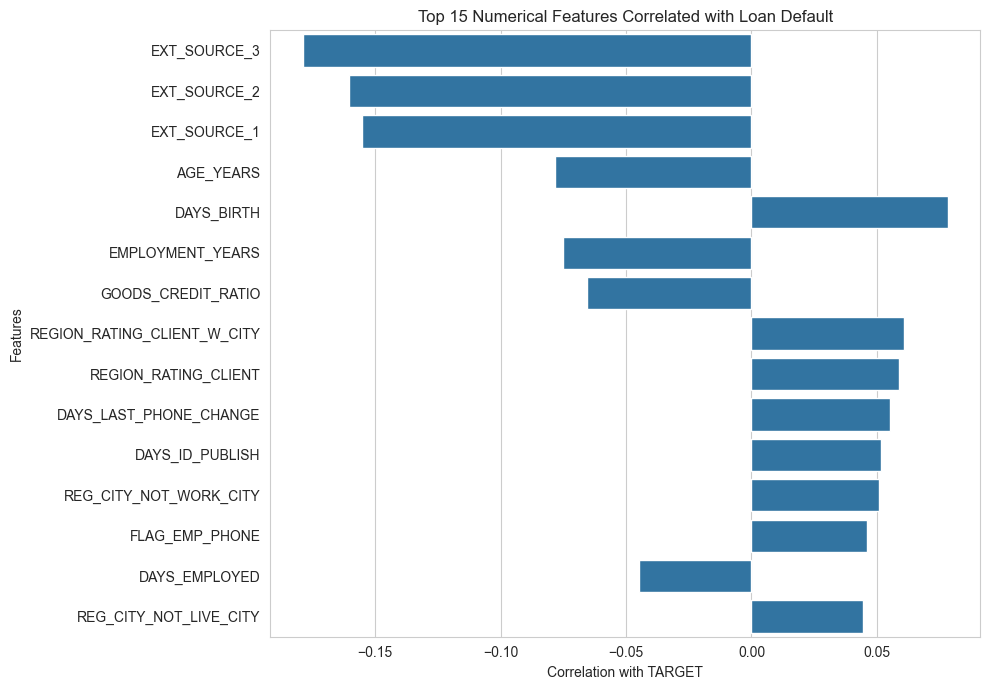

In [53]:
top_features = target_correlation.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    x=top_features.values,
    y=top_features.index
)

plt.title("Top 15 Numerical Features Correlated with Loan Default")
plt.xlabel("Correlation with TARGET")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

Step 19 – Analyse EXT_SOURCE features in more detail

In [54]:
ext_columns = [
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3"
]

ext_missing = pd.DataFrame({
    "Feature": ext_columns,
    "Missing_Count": [
        application_train[col].isnull().sum()
        for col in ext_columns
    ],
    "Missing_Percentage": [
        application_train[col].isnull().mean() * 100
        for col in ext_columns
    ]
})

display(ext_missing.round(2))

,Feature,Missing_Count,Missing_Percentage
0,EXT_SOURCE_1,173378,56.38
1,EXT_SOURCE_2,660,0.21
2,EXT_SOURCE_3,60965,19.83


In [55]:
for column in ext_columns:

    print("\nDefault rate analysis:", column)

    score_groups = pd.qcut(
        application_train[column],
        q=5,
        duplicates="drop"
    )

    analysis_df = pd.DataFrame({
        "Score_Group": score_groups,
        "TARGET": application_train["TARGET"]
    })

    group_analysis = analysis_df.groupby(
        "Score_Group",
        observed=True
    )["TARGET"].agg(
        ["count", "mean"]
    )

    group_analysis["Default_Rate_Percentage"] = (
        group_analysis["mean"] * 100
    )

    display(group_analysis.round(2))


Default rate analysis: EXT_SOURCE_1


,count,mean,Default_Rate_Percentage
Score_Group,,,
"(0.013600000000000001, 0.296]",26827,0.15,14.58
"(0.296, 0.438]",26826,0.09,8.74
"(0.438, 0.573]",26827,0.06,6.36
"(0.573, 0.71]",26826,0.05,4.76
"(0.71, 0.963]",26827,0.03,3.04



Default rate analysis: EXT_SOURCE_2


,count,mean,Default_Rate_Percentage
Score_Group,,,
"(-0.0009999183, 0.34]",61371,0.15,15.21
"(0.34, 0.512]",61371,0.09,9.16
"(0.512, 0.608]",61371,0.07,7.04
"(0.608, 0.682]",61377,0.05,5.37
"(0.682, 0.855]",61361,0.04,3.59



Default rate analysis: EXT_SOURCE_3


,count,mean,Default_Rate_Percentage
Score_Group,,,
"(-0.000473, 0.33]",49445,0.16,16.38
"(0.33, 0.476]",49746,0.09,8.75
"(0.476, 0.592]",49578,0.06,5.75
"(0.592, 0.694]",49470,0.04,4.48
"(0.694, 0.896]",48307,0.03,3.38


Step 20 – Check whether missing EXT_SOURCE values matter

In [56]:
for column in ext_columns:

    print("\nMissing-value analysis:", column)

    missing_analysis = application_train.groupby(
        application_train[column].isna()
    )["TARGET"].agg(
        ["count", "mean"]
    )

    missing_analysis.index = [
        "Available values",
        "Missing values"
    ]

    missing_analysis["Default_Rate_Percentage"] = (
        missing_analysis["mean"] * 100
    )

    display(missing_analysis.round(2))


Missing-value analysis: EXT_SOURCE_1


,count,mean,Default_Rate_Percentage
Available values,134133,0.07,7.50
Missing values,173378,0.09,8.52



Missing-value analysis: EXT_SOURCE_2


,count,mean,Default_Rate_Percentage
Available values,306851,0.08,8.07
Missing values,660,0.08,7.88



Missing-value analysis: EXT_SOURCE_3


,count,mean,Default_Rate_Percentage
Available values,246546,0.08,7.77
Missing values,60965,0.09,9.31


Step 21 – Prepare the main dataset

In [57]:
# Create a working copy
df = application_train.copy()

print("Original dataset shape:", application_train.shape)
print("Working dataset shape:", df.shape)

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["SK_ID_CURR"].duplicated().sum())
print("Target missing values:", df["TARGET"].isnull().sum())

Original dataset shape: (307511, 128)
Working dataset shape: (307511, 128)

Duplicate rows: 0
Duplicate customer IDs: 0
Target missing values: 0


Step 22 – Handle special values and unnecessary columns

In [58]:
# Separate target
y = df["TARGET"].copy()

# Remove ID and original employment-days column
X = df.drop(
    columns=["TARGET", "SK_ID_CURR", "DAYS_EMPLOYED"]
)

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature dataset shape: (307511, 125)
Target dataset shape: (307511,)

Target distribution:
TARGET
0    282686
1     24825
Name: count, dtype: int64


Step 23 – Check categorical and numerical columns

In [59]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("\nCategorical columns:")
print(categorical_features)

Numerical features: 108
Categorical features: 16

Categorical columns:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


Step 24 – Split training and testing data

In [60]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(4))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(4))

Training features: (246008, 125)
Testing features: (61503, 125)

Training target distribution:
TARGET
0    0.9193
1    0.0807
Name: proportion, dtype: float64

Testing target distribution:
TARGET
0    0.9193
1    0.0807
Name: proportion, dtype: float64


Step 25 – Build preprocessing pipeline

In [65]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    sparse_threshold=1.0
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


Step 26: Apply preprocessing

In [66]:
# Fit preprocessing on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same preprocessing to testing data
X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

print("\nPreprocessing completed successfully!")

Training data shape: (246008, 248)
Testing data shape: (61503, 248)

Preprocessing completed successfully!


Step 27: Train multiple machine learning models

In [67]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import pandas as pd
import time

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )
}

results = []

# Train and evaluate each model
for name, model in models.items():

    print(f"\nTraining {name}...")
    start_time = time.time()

    model.fit(X_train_processed, y_train)

    y_pred = model.predict(X_test_processed)
    y_probability = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_probability),
        "Training Time (seconds)": round(time.time() - start_time, 2)
    })

    print(f"{name} completed!")

# Display comparison
model_comparison = pd.DataFrame(results)

model_comparison = model_comparison.sort_values(
    by="ROC-AUC",
    ascending=False
)

display(model_comparison.round(4))


Training Logistic Regression...
Logistic Regression completed!

Training Decision Tree...
Decision Tree completed!

Training Random Forest...
Random Forest completed!


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (seconds)
0,Logistic Regression,0.6900,0.1617,0.6783,0.2611,0.7491,5.09
2,Random Forest,0.8107,0.1985,0.4425,0.2740,0.7235,36.58
1,Decision Tree,0.6466,0.1387,0.6483,0.2285,0.6782,20.09


Step 29: Create a classification report


Logistic Regression
               precision    recall  f1-score   support

Non-Defaulter       0.96      0.69      0.80     56538
    Defaulter       0.16      0.68      0.26      4965

     accuracy                           0.69     61503
    macro avg       0.56      0.68      0.53     61503
 weighted avg       0.90      0.69      0.76     61503



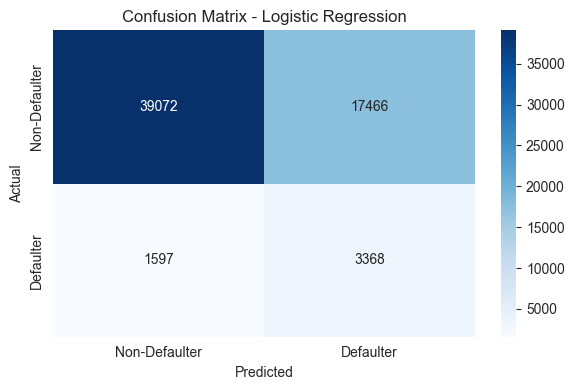


Decision Tree
               precision    recall  f1-score   support

Non-Defaulter       0.95      0.65      0.77     56538
    Defaulter       0.14      0.65      0.23      4965

     accuracy                           0.65     61503
    macro avg       0.55      0.65      0.50     61503
 weighted avg       0.89      0.65      0.73     61503



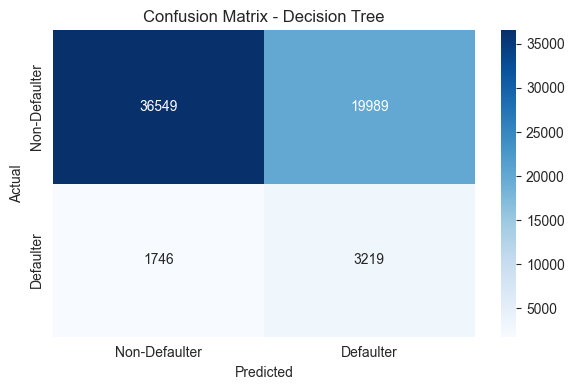


Random Forest
               precision    recall  f1-score   support

Non-Defaulter       0.95      0.84      0.89     56538
    Defaulter       0.20      0.44      0.27      4965

     accuracy                           0.81     61503
    macro avg       0.57      0.64      0.58     61503
 weighted avg       0.88      0.81      0.84     61503



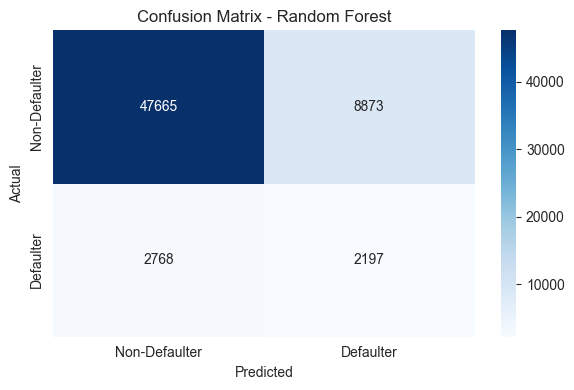

In [68]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

for name, model in models.items():

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    y_pred = model.predict(X_test_processed)

    print(classification_report(
        y_test,
        y_pred,
        target_names=["Non-Defaulter", "Defaulter"]
    ))

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Non-Defaulter", "Defaulter"],
        yticklabels=["Non-Defaulter", "Defaulter"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

Step 31: Improve Logistic Regression using a classification threshold

In [69]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Get predicted probabilities
logistic_model = models["Logistic Regression"]

y_prob = logistic_model.predict_proba(X_test_processed)[:, 1]

# Test different classification thresholds
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

threshold_results = []

for threshold in thresholds:

    y_threshold_pred = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_threshold_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_threshold_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_threshold_pred, zero_division=0
        )
    })

threshold_comparison = pd.DataFrame(threshold_results)

display(threshold_comparison.round(4))

,Threshold,Precision,Recall,F1 Score
0,0.30,0.1084,0.9104,0.1937
1,0.35,0.1195,0.8647,0.2100
2,0.40,0.1325,0.8119,0.2278
3,0.45,0.1460,0.7476,0.2443
4,0.50,0.1617,0.6783,0.2611
5,0.55,0.1796,0.5994,0.2764
6,0.60,0.1997,0.5150,0.2878


Step 33: Evaluate Logistic Regression at threshold 0.60

Logistic Regression - Threshold 0.60
               precision    recall  f1-score   support

Non-Defaulter       0.95      0.82      0.88     56538
    Defaulter       0.20      0.52      0.29      4965

     accuracy                           0.79     61503
    macro avg       0.58      0.67      0.58     61503
 weighted avg       0.89      0.79      0.83     61503



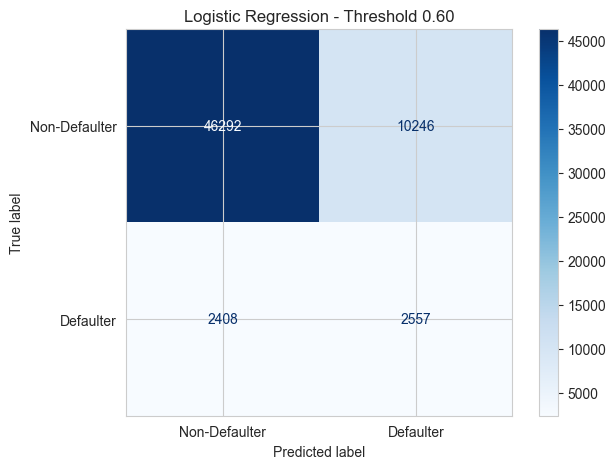

In [70]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Apply selected threshold
best_threshold = 0.60

y_pred_best = (y_prob >= best_threshold).astype(int)

# Classification report
print("Logistic Regression - Threshold 0.60")
print(classification_report(
    y_test,
    y_pred_best,
    target_names=["Non-Defaulter", "Defaulter"]
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_best)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Defaulter", "Defaulter"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Threshold 0.60")
plt.tight_layout()
plt.show()

Step 34: Save the threshold comparison

In [71]:
threshold_comparison.to_csv(
    "threshold_comparison.csv",
    index=False
)

print("Threshold comparison saved successfully!")

Threshold comparison saved successfully!


Step 35: Feature importance using Logistic Regression

In [72]:
# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = logistic_model.coef_[0]

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Importance": abs(coefficients)
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 20 features
display(feature_importance.head(20).round(4))

,Feature,Coefficient,Importance
210,cat__ORGANIZATION_TYPE_Realtor,0.8205,0.8205
203,cat__ORGANIZATION_TYPE_Legal Services,0.6510,0.6510
132,cat__NAME_EDUCATION_TYPE_Academic degree,-0.6095,0.6095
127,cat__NAME_INCOME_TYPE_Pensioner,-0.5363,0.5363
228,cat__ORGANIZATION_TYPE_Transport: type 3,0.5243,0.5243
205,cat__ORGANIZATION_TYPE_Military,-0.4825,0.4825
28,num__EXT_SOURCE_3,-0.4814,0.4814
191,cat__ORGANIZATION_TYPE_Industry: type 12,-0.4507,0.4507
130,cat__NAME_INCOME_TYPE_Unemployed,0.4426,0.4426
224,cat__ORGANIZATION_TYPE_Trade: type 6,-0.4404,0.4404


Step 36: Visualize the top 15 features

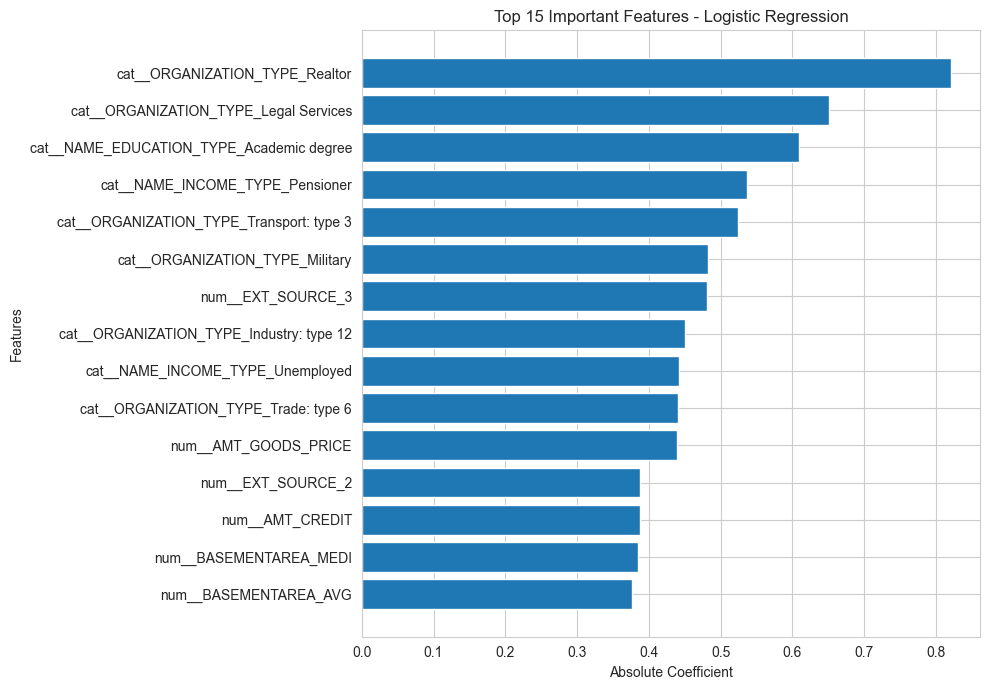

In [73]:
top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Absolute Coefficient")
plt.ylabel("Features")
plt.title("Top 15 Important Features - Logistic Regression")

plt.tight_layout()
plt.show()

Step 38: Create a positive and negative feature importance chart

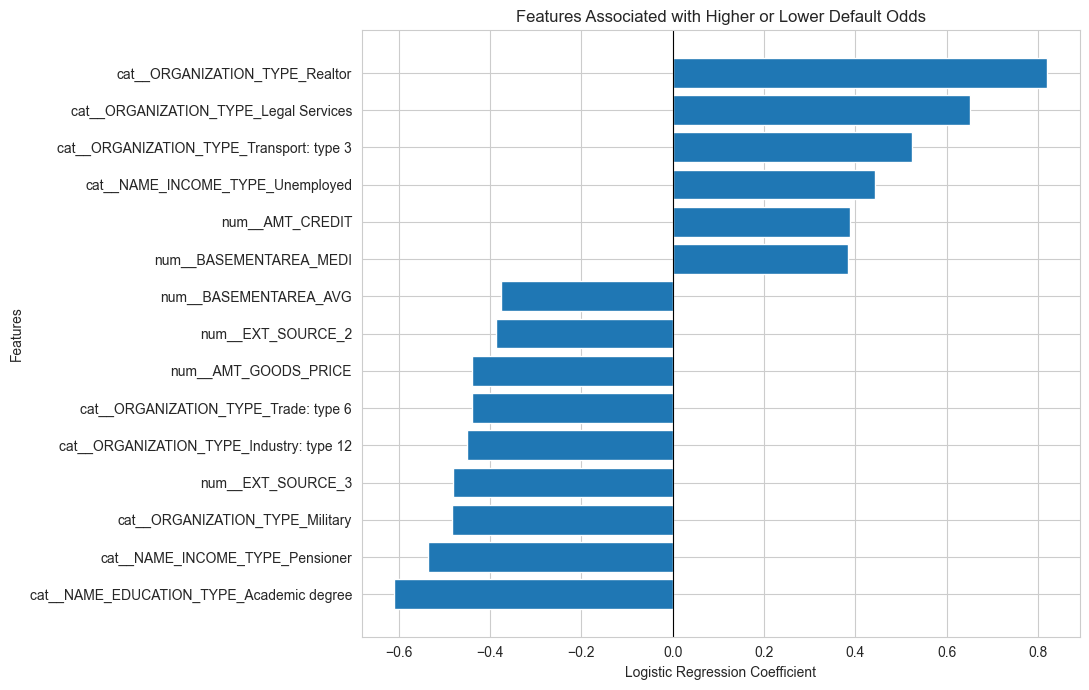

In [74]:
# Select top 15 features by absolute coefficient
top_features = feature_importance.head(15).copy()

# Separate positive and negative coefficients
top_features = top_features.sort_values(
    by="Coefficient"
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(x=0, color="black", linewidth=0.8)

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Features")
plt.title("Features Associated with Higher or Lower Default Odds")

plt.tight_layout()
plt.show()

Step 39: Save feature importance results

In [75]:
feature_importance.to_csv(
    "feature_importance.csv",
    index=False
)

print("Feature importance report saved successfully!")

Feature importance report saved successfully!


Step 40: Analyse Bureau Balance

In [76]:
# Step 40: Bureau Balance aggregation

# Convert credit status into numeric values
bureau_balance["STATUS_NUM"] = pd.to_numeric(
    bureau_balance["STATUS"],
    errors="coerce"
)

# Aggregate monthly credit information by previous credit ID
bureau_balance_features = bureau_balance.groupby(
    "SK_ID_BUREAU"
).agg(
    BB_MONTHS_COUNT=("MONTHS_BALANCE", "count"),
    BB_MONTHS_MIN=("MONTHS_BALANCE", "min"),
    BB_MONTHS_MAX=("MONTHS_BALANCE", "max"),
    BB_STATUS_MEAN=("STATUS_NUM", "mean"),
    BB_STATUS_MAX=("STATUS_NUM", "max")
).reset_index()

print("Bureau Balance features shape:", bureau_balance_features.shape)
display(bureau_balance_features.head())

Bureau Balance features shape: (817395, 6)


,SK_ID_BUREAU,BB_MONTHS_COUNT,BB_MONTHS_MIN,BB_MONTHS_MAX,BB_STATUS_MEAN,BB_STATUS_MAX
0,5001709,97,-96,0,NaN,NaN
1,5001710,83,-82,0,0.0,0.0
2,5001711,4,-3,0,0.0,0.0
3,5001712,19,-18,0,0.0,0.0
4,5001713,22,-21,0,NaN,NaN


Step 41: Aggregate Bureau data

In [77]:
# Merge Bureau with Bureau Balance features
bureau_combined = bureau.merge(
    bureau_balance_features,
    on="SK_ID_BUREAU",
    how="left"
)

# Select numeric columns, excluding IDs
bureau_numeric_cols = bureau_combined.select_dtypes(
    include=["number"]
).columns.tolist()

bureau_numeric_cols = [
    col for col in bureau_numeric_cols
    if col not in ["SK_ID_CURR", "SK_ID_BUREAU"]
]

# Aggregate previous credit information by customer
bureau_features = bureau_combined.groupby(
    "SK_ID_CURR"
)[bureau_numeric_cols].agg(
    ["mean", "max", "min"]
)

# Flatten column names
bureau_features.columns = [
    "BUREAU_" + col + "_" + stat
    for col, stat in bureau_features.columns
]

bureau_features = bureau_features.reset_index()

# Add total previous credit count
bureau_count = bureau.groupby(
    "SK_ID_CURR"
).size().reset_index(name="BUREAU_TOTAL_CREDITS")

bureau_features = bureau_features.merge(
    bureau_count,
    on="SK_ID_CURR",
    how="left"
)

print("Bureau features shape:", bureau_features.shape)
display(bureau_features.head())

Bureau features shape: (305811, 53)


,SK_ID_CURR,BUREAU_DAYS_CREDIT_mean,BUREAU_DAYS_CREDIT_max,BUREAU_DAYS_CREDIT_min,BUREAU_CREDIT_DAY_OVERDUE_mean,BUREAU_CREDIT_DAY_OVERDUE_max,BUREAU_CREDIT_DAY_OVERDUE_min,BUREAU_DAYS_CREDIT_ENDDATE_mean,BUREAU_DAYS_CREDIT_ENDDATE_max,BUREAU_DAYS_CREDIT_ENDDATE_min,...,BUREAU_BB_MONTHS_MAX_mean,BUREAU_BB_MONTHS_MAX_max,BUREAU_BB_MONTHS_MAX_min,BUREAU_BB_STATUS_MEAN_mean,BUREAU_BB_STATUS_MEAN_max,BUREAU_BB_STATUS_MEAN_min,BUREAU_BB_STATUS_MAX_mean,BUREAU_BB_STATUS_MAX_max,BUREAU_BB_STATUS_MAX_min,BUREAU_TOTAL_CREDITS
0,100001,-735.000000,-49,-1572,0.0,0,0,82.428571,1778.0,-1329.0,...,0.0,0.0,0.0,0.010989,0.076923,0.0,0.142857,1.0,0.0,7
1,100002,-874.000000,-103,-1437,0.0,0,0,-349.000000,780.0,-1072.0,...,-15.5,0.0,-32.0,0.341806,0.545455,0.0,0.750000,1.0,0.0,8
2,100003,-1400.750000,-606,-2586,0.0,0,0,-544.500000,1216.0,-2434.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4
3,100004,-867.000000,-408,-1326,0.0,0,0,-488.500000,-382.0,-595.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
4,100005,-190.666667,-62,-373,0.0,0,0,439.333333,1324.0,-128.0,...,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,3


Step 42: Previous Application analysis

In [78]:
# Step 42: Previous Application aggregation

# Numeric features to aggregate
previous_numeric_cols = [
    "AMT_APPLICATION",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_DOWN_PAYMENT",
    "RATE_DOWN_PAYMENT",
    "DAYS_DECISION",
    "CNT_PAYMENT"
]

# Calculate customer-level statistics
previous_features = previous_application.groupby(
    "SK_ID_CURR"
)[previous_numeric_cols].agg(
    ["mean", "max", "min"]
)

# Flatten column names
previous_features.columns = [
    "PREV_" + col + "_" + stat
    for col, stat in previous_features.columns
]

previous_features = previous_features.reset_index()

# Count previous applications by status
status_counts = pd.crosstab(
    previous_application["SK_ID_CURR"],
    previous_application["NAME_CONTRACT_STATUS"]
).reset_index()

status_counts.columns = [
    "SK_ID_CURR"
] + [
    "PREV_STATUS_" + str(col).replace(" ", "_")
    for col in status_counts.columns[1:]
]

# Merge status counts
previous_features = previous_features.merge(
    status_counts,
    on="SK_ID_CURR",
    how="left"
)

# Total previous applications
previous_count = previous_application.groupby(
    "SK_ID_CURR"
).size().reset_index(name="PREV_TOTAL_APPLICATIONS")

previous_features = previous_features.merge(
    previous_count,
    on="SK_ID_CURR",
    how="left"
)

print("Previous Application features shape:", previous_features.shape)
display(previous_features.head())

Previous Application features shape: (338857, 27)


,SK_ID_CURR,PREV_AMT_APPLICATION_mean,PREV_AMT_APPLICATION_max,PREV_AMT_APPLICATION_min,PREV_AMT_CREDIT_mean,PREV_AMT_CREDIT_max,PREV_AMT_CREDIT_min,PREV_AMT_ANNUITY_mean,PREV_AMT_ANNUITY_max,PREV_AMT_ANNUITY_min,...,PREV_DAYS_DECISION_max,PREV_DAYS_DECISION_min,PREV_CNT_PAYMENT_mean,PREV_CNT_PAYMENT_max,PREV_CNT_PAYMENT_min,PREV_STATUS_Approved,PREV_STATUS_Canceled,PREV_STATUS_Refused,PREV_STATUS_Unused_offer,PREV_TOTAL_APPLICATIONS
0,100001,24835.50,24835.5,24835.5,23787.00,23787.0,23787.0,3951.000,3951.000,3951.000,...,-1740,-1740,8.0,8.0,8.0,1,0,0,0,1
1,100002,179055.00,179055.0,179055.0,179055.00,179055.0,179055.0,9251.775,9251.775,9251.775,...,-606,-606,24.0,24.0,24.0,1,0,0,0,1
2,100003,435436.50,900000.0,68809.5,484191.00,1035882.0,68053.5,56553.990,98356.995,6737.310,...,-746,-2341,10.0,12.0,6.0,3,0,0,0,3
3,100004,24282.00,24282.0,24282.0,20106.00,20106.0,20106.0,5357.250,5357.250,5357.250,...,-815,-815,4.0,4.0,4.0,1,0,0,0,1
4,100005,22308.75,44617.5,0.0,20076.75,40153.5,0.0,4813.200,4813.200,4813.200,...,-315,-757,12.0,12.0,12.0,1,1,0,0,2


Step 43: POS Cash Balance aggregation

In [79]:
# Step 43: POS Cash Balance aggregation

pos_numeric_cols = [
    "MONTHS_BALANCE",
    "CNT_INSTALMENT",
    "CNT_INSTALMENT_FUTURE",
    "SK_DPD",
    "SK_DPD_DEF"
]

pos_features = pos_cash.groupby(
    "SK_ID_CURR"
)[pos_numeric_cols].agg(
    ["mean", "max", "min"]
)

pos_features.columns = [
    "POS_" + col + "_" + stat
    for col, stat in pos_features.columns
]

pos_features = pos_features.reset_index()

# Count POS records per customer
pos_count = pos_cash.groupby(
    "SK_ID_CURR"
).size().reset_index(name="POS_TOTAL_RECORDS")

pos_features = pos_features.merge(
    pos_count,
    on="SK_ID_CURR",
    how="left"
)

print("POS Cash features shape:", pos_features.shape)
display(pos_features.head())

POS Cash features shape: (337252, 17)


,SK_ID_CURR,POS_MONTHS_BALANCE_mean,POS_MONTHS_BALANCE_max,POS_MONTHS_BALANCE_min,POS_CNT_INSTALMENT_mean,POS_CNT_INSTALMENT_max,POS_CNT_INSTALMENT_min,POS_CNT_INSTALMENT_FUTURE_mean,POS_CNT_INSTALMENT_FUTURE_max,POS_CNT_INSTALMENT_FUTURE_min,POS_SK_DPD_mean,POS_SK_DPD_max,POS_SK_DPD_min,POS_SK_DPD_DEF_mean,POS_SK_DPD_DEF_max,POS_SK_DPD_DEF_min,POS_TOTAL_RECORDS
0,100001,-72.555556,-53,-96,4.000000,4.0,4.0,1.444444,4.0,0.0,0.777778,7,0,0.777778,7,0,9
1,100002,-10.000000,-1,-19,24.000000,24.0,24.0,15.000000,24.0,6.0,0.000000,0,0,0.000000,0,0,19
2,100003,-43.785714,-18,-77,10.107143,12.0,6.0,5.785714,12.0,0.0,0.000000,0,0,0.000000,0,0,28
3,100004,-25.500000,-24,-27,3.750000,4.0,3.0,2.250000,4.0,0.0,0.000000,0,0,0.000000,0,0,4
4,100005,-20.000000,-15,-25,11.700000,12.0,9.0,7.200000,12.0,0.0,0.000000,0,0,0.000000,0,0,11


Step 44: Credit Card Balance aggregation

In [80]:
# Step 44: Credit Card Balance aggregation

credit_numeric_cols = [
    "AMT_BALANCE",
    "AMT_CREDIT_LIMIT_ACTUAL",
    "AMT_DRAWINGS_CURRENT",
    "AMT_PAYMENT_CURRENT",
    "AMT_TOTAL_RECEIVABLE",
    "CNT_DRAWINGS_CURRENT",
    "SK_DPD",
    "SK_DPD_DEF"
]

credit_features = credit_card.groupby(
    "SK_ID_CURR"
)[credit_numeric_cols].agg(
    ["mean", "max", "min"]
)

credit_features.columns = [
    "CC_" + col + "_" + stat
    for col, stat in credit_features.columns
]

credit_features = credit_features.reset_index()

# Count credit card records per customer
credit_count = credit_card.groupby(
    "SK_ID_CURR"
).size().reset_index(name="CC_TOTAL_RECORDS")

credit_features = credit_features.merge(
    credit_count,
    on="SK_ID_CURR",
    how="left"
)

print("Credit Card features shape:", credit_features.shape)
display(credit_features.head())

Credit Card features shape: (103558, 26)


,SK_ID_CURR,CC_AMT_BALANCE_mean,CC_AMT_BALANCE_max,CC_AMT_BALANCE_min,CC_AMT_CREDIT_LIMIT_ACTUAL_mean,CC_AMT_CREDIT_LIMIT_ACTUAL_max,CC_AMT_CREDIT_LIMIT_ACTUAL_min,CC_AMT_DRAWINGS_CURRENT_mean,CC_AMT_DRAWINGS_CURRENT_max,CC_AMT_DRAWINGS_CURRENT_min,...,CC_CNT_DRAWINGS_CURRENT_mean,CC_CNT_DRAWINGS_CURRENT_max,CC_CNT_DRAWINGS_CURRENT_min,CC_SK_DPD_mean,CC_SK_DPD_max,CC_SK_DPD_min,CC_SK_DPD_DEF_mean,CC_SK_DPD_DEF_max,CC_SK_DPD_DEF_min,CC_TOTAL_RECORDS
0,100006,0.000000,0.00,0.0,270000.000000,270000,270000,0.000000,0.0,0.0,...,0.000000,0,0,0.000000,0,0,0.000000,0,0,6
1,100011,54482.111149,189000.00,0.0,164189.189189,180000,90000,2432.432432,180000.0,0.0,...,0.054054,4,0,0.000000,0,0,0.000000,0,0,74
2,100013,18159.919219,161420.22,0.0,131718.750000,157500,45000,5953.125000,157500.0,0.0,...,0.239583,7,0,0.010417,1,0,0.010417,1,0,96
3,100021,0.000000,0.00,0.0,675000.000000,675000,675000,0.000000,0.0,0.0,...,0.000000,0,0,0.000000,0,0,0.000000,0,0,17
4,100023,0.000000,0.00,0.0,135000.000000,225000,45000,0.000000,0.0,0.0,...,0.000000,0,0,0.000000,0,0,0.000000,0,0,8


Step 45: Installments Payments aggregation

In [81]:
# Step 45: Installments Payments aggregation

# Calculate payment delay
installments["PAYMENT_DELAY"] = (
    installments["DAYS_ENTRY_PAYMENT"] -
    installments["DAYS_INSTALMENT"]
)

# Calculate payment ratio
installments["PAYMENT_RATIO"] = (
    installments["AMT_PAYMENT"] /
    installments["AMT_INSTALMENT"].replace(0, np.nan)
)

installment_features = installments.groupby(
    "SK_ID_CURR"
).agg(
    INSTALMENT_TOTAL_RECORDS=("SK_ID_PREV", "count"),
    INSTALMENT_AMOUNT_MEAN=("AMT_INSTALMENT", "mean"),
    INSTALMENT_AMOUNT_MAX=("AMT_INSTALMENT", "max"),
    PAYMENT_AMOUNT_MEAN=("AMT_PAYMENT", "mean"),
    PAYMENT_DELAY_MEAN=("PAYMENT_DELAY", "mean"),
    PAYMENT_DELAY_MAX=("PAYMENT_DELAY", "max"),
    PAYMENT_RATIO_MEAN=("PAYMENT_RATIO", "mean"),
    PAYMENT_RATIO_MIN=("PAYMENT_RATIO", "min")
).reset_index()

print("Installment features shape:", installment_features.shape)
display(installment_features.head())

Installment features shape: (339587, 9)


,SK_ID_CURR,INSTALMENT_TOTAL_RECORDS,INSTALMENT_AMOUNT_MEAN,INSTALMENT_AMOUNT_MAX,PAYMENT_AMOUNT_MEAN,PAYMENT_DELAY_MEAN,PAYMENT_DELAY_MAX,PAYMENT_RATIO_MEAN,PAYMENT_RATIO_MIN
0,100001,7,5885.132143,17397.900,5885.132143,-7.285714,11.0,1.0,1.0
1,100002,19,11559.247105,53093.745,11559.247105,-20.421053,-12.0,1.0,1.0
2,100003,25,64754.586000,560835.360,64754.586000,-7.160000,-1.0,1.0,1.0
3,100004,3,7096.155000,10573.965,7096.155000,-7.666667,-3.0,1.0,1.0
4,100005,9,6240.205000,17656.245,6240.205000,-23.555556,1.0,1.0,1.0


Step 46: Check all six supplementary feature datasets

In [82]:
feature_datasets = {
    "Bureau": bureau_features,
    "Previous Application": previous_features,
    "POS Cash": pos_features,
    "Credit Card": credit_features,
    "Installments": installment_features
}

for name, data in feature_datasets.items():
    print(
        name,
        "| Shape:", data.shape,
        "| Duplicate customer IDs:", data["SK_ID_CURR"].duplicated().sum()
    )

Bureau | Shape: (305811, 53) | Duplicate customer IDs: 0
Previous Application | Shape: (338857, 27) | Duplicate customer IDs: 0
POS Cash | Shape: (337252, 17) | Duplicate customer IDs: 0
Credit Card | Shape: (103558, 26) | Duplicate customer IDs: 0
Installments | Shape: (339587, 9) | Duplicate customer IDs: 0


Step 47: Combine all supplementary features

In [83]:
# Start with main application dataset
final_df = application_train.copy()

# Merge supplementary datasets
for name, data in feature_datasets.items():

    final_df = final_df.merge(
        data,
        on="SK_ID_CURR",
        how="left",
        validate="one_to_one"
    )

    print(name, "merged successfully:", final_df.shape)

print("\nFinal combined dataset shape:", final_df.shape)
print("Duplicate customer IDs:", final_df["SK_ID_CURR"].duplicated().sum())

Bureau merged successfully: (307511, 180)
Previous Application merged successfully: (307511, 206)
POS Cash merged successfully: (307511, 222)
Credit Card merged successfully: (307511, 247)
Installments merged successfully: (307511, 255)

Final combined dataset shape: (307511, 255)
Duplicate customer IDs: 0


Step 48: Prepare final combined dataset for modelling

In [84]:
# Step 48: Prepare final features and target

# Create working copy
model_df = final_df.copy()

# Remove exploratory and identifier columns
columns_to_drop = [
    "TARGET",
    "SK_ID_CURR",
    "DAYS_EMPLOYED",
    "DAYS_BIRTH",
    "AGE_GROUP"
]

X_final = model_df.drop(
    columns=columns_to_drop,
    errors="ignore"
)

y_final = model_df["TARGET"].copy()

# Identify numerical and categorical features
numeric_features_final = X_final.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features_final = X_final.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Final feature shape:", X_final.shape)
print("Target shape:", y_final.shape)
print("Numerical features:", len(numeric_features_final))
print("Categorical features:", len(categorical_features_final))

Final feature shape: (307511, 250)
Target shape: (307511,)
Numerical features: 234
Categorical features: 16


Step 49: Split final data

In [85]:
from sklearn.model_selection import train_test_split

X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(
    X_final,
    y_final,
    test_size=0.20,
    random_state=42,
    stratify=y_final
)

print("Training shape:", X_train_final.shape)
print("Testing shape:", X_test_final.shape)

Training shape: (246008, 250)
Testing shape: (61503, 250)


Step 50: Create final preprocessing pipeline

In [86]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_transformer_final = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer_final = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

preprocessor_final = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_final, numeric_features_final),
        ("cat", categorical_transformer_final, categorical_features_final)
    ],
    sparse_threshold=1.0
)

print("Final preprocessing pipeline created!")

Final preprocessing pipeline created!


Step 51: Apply preprocessing

In [87]:
X_train_final_processed = preprocessor_final.fit_transform(
    X_train_final
)

X_test_final_processed = preprocessor_final.transform(
    X_test_final
)

print("Training processed shape:", X_train_final_processed.shape)
print("Testing processed shape:", X_test_final_processed.shape)
print("Final preprocessing completed!")

Training processed shape: (246008, 374)
Testing processed shape: (61503, 374)
Final preprocessing completed!


Step 52: Train final machine learning models

In [88]:
# Step 52: Final model training and comparison

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import pandas as pd
import time

final_models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )
}

final_results = []

for name, model in final_models.items():

    print(f"\nTraining {name}...")

    start_time = time.time()

    model.fit(X_train_final_processed, y_train_final)

    y_pred = model.predict(X_test_final_processed)
    y_prob = model.predict_proba(X_test_final_processed)[:, 1]

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_final, y_pred),
        "Precision": precision_score(y_test_final, y_pred, zero_division=0),
        "Recall": recall_score(y_test_final, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test_final, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test_final, y_prob),
        "Training Time (seconds)": round(time.time() - start_time, 2)
    })

    print(f"{name} completed!")

final_model_comparison = pd.DataFrame(final_results)

final_model_comparison = final_model_comparison.sort_values(
    by="ROC-AUC",
    ascending=False
)

display(final_model_comparison.round(4))


Training Logistic Regression...
Logistic Regression completed!

Training Decision Tree...
Decision Tree completed!

Training Random Forest...
Random Forest completed!


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (seconds)
0,Logistic Regression,0.7047,0.1721,0.6975,0.2761,0.7694,11.45
2,Random Forest,0.8578,0.2372,0.3438,0.2807,0.7428,68.65
1,Decision Tree,0.6620,0.1406,0.6234,0.2295,0.6703,45.44


Step 53: Save final model comparison

In [89]:
final_model_comparison.to_csv(
    "final_model_comparison.csv",
    index=False
)

print("Final model comparison saved successfully!")

Final model comparison saved successfully!


Step 55: Detailed evaluation of the final Logistic Regression model

               precision    recall  f1-score   support

Non-Defaulter       0.96      0.71      0.81     56538
    Defaulter       0.17      0.70      0.28      4965

     accuracy                           0.70     61503
    macro avg       0.57      0.70      0.55     61503
 weighted avg       0.90      0.70      0.77     61503



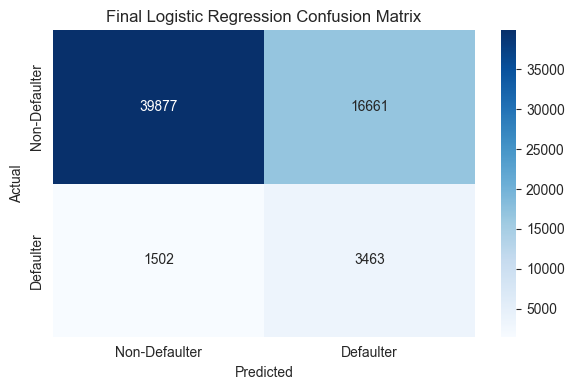

In [90]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Final Logistic Regression model
final_logistic_model = final_models["Logistic Regression"]

# Predictions
final_y_pred = final_logistic_model.predict(X_test_final_processed)
final_y_prob = final_logistic_model.predict_proba(
    X_test_final_processed
)[:, 1]

# Classification report
print(classification_report(
    y_test_final,
    final_y_pred,
    target_names=["Non-Defaulter", "Defaulter"]
))

# Confusion matrix
cm = confusion_matrix(y_test_final, final_y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Defaulter", "Defaulter"],
    yticklabels=["Non-Defaulter", "Defaulter"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

Step 56: Final threshold comparison

In [91]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

final_threshold_results = []

for threshold in thresholds:

    predictions = (final_y_prob >= threshold).astype(int)

    final_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test_final, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_final, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test_final, predictions, zero_division=0
        )
    })

final_threshold_comparison = pd.DataFrame(final_threshold_results)

display(final_threshold_comparison.round(4))

,Threshold,Precision,Recall,F1 Score
0,0.30,0.1156,0.9033,0.2050
1,0.35,0.1273,0.8618,0.2218
2,0.40,0.1414,0.8151,0.2411
3,0.45,0.1568,0.7617,0.2601
4,0.50,0.1721,0.6975,0.2761
5,0.55,0.1894,0.6240,0.2906
6,0.60,0.2133,0.5515,0.3076


In [92]:
final_threshold_comparison.to_csv(
    "final_threshold_comparison.csv",
    index=False
)

print("Final threshold comparison saved!")

Final threshold comparison saved!


Step 57: Save final model and preprocessing

In [93]:
import joblib

joblib.dump(
    final_logistic_model,
    "home_loan_logistic_model.pkl"
)

joblib.dump(
    preprocessor_final,
    "home_loan_preprocessor.pkl"
)

print("Final model saved successfully!")
print("Preprocessor saved successfully!")

Final model saved successfully!
Preprocessor saved successfully!


Model Comparison Report
Project: Home Loan Default Risk Management

Three machine learning algorithms were evaluated: Logistic Regression, Decision Tree and Random Forest.
Model	Accuracy	Precision	Recall	F1 Score	ROC-AUC
Logistic Regression	70.47%	17.21%	69.75%	27.61%	76.94%
Random Forest	85.78%	23.72%	34.38%	28.07%	74.28%
Decision Tree	66.20%	14.06%	62.34%	22.95%	67.03%

Step 59 — Final feature importance

In [94]:
# Get feature names after preprocessing
feature_names_final = preprocessor_final.get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = final_logistic_model.coef_[0]

# Create feature importance table
final_feature_importance = pd.DataFrame({
    "Feature": feature_names_final,
    "Coefficient": coefficients,
    "Importance": np.abs(coefficients)
})

# Sort by absolute importance
final_feature_importance = final_feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(final_feature_importance.head(20))

# Save results
final_feature_importance.to_csv(
    "final_feature_importance.csv",
    index=False
)

print("Final feature importance saved successfully!")

,Feature,Coefficient,Importance
184,num__PREV_TOTAL_APPLICATIONS,0.958225,0.958225
336,cat__ORGANIZATION_TYPE_Realtor,0.793778,0.793778
229,num__PAYMENT_AMOUNT_MEAN,-0.663321,0.663321
180,num__PREV_STATUS_Approved,-0.648267,0.648267
329,cat__ORGANIZATION_TYPE_Legal Services,0.636671,0.636671
227,num__INSTALMENT_AMOUNT_MEAN,0.572137,0.572137
188,num__POS_CNT_INSTALMENT_mean,-0.529268,0.529268
191,num__POS_CNT_INSTALMENT_FUTURE_mean,0.528009,0.528009
354,cat__ORGANIZATION_TYPE_Transport: type 3,0.517480,0.517480
4,num__AMT_GOODS_PRICE,-0.508503,0.508503


Final feature importance saved successfully!


Step 60 — Add the final project report

# Home Loan Default Risk Management — Final Project Report

## 1. Project Objective

The objective of this project is to analyse home loan applicant data and develop a machine learning model that can identify customers who are likely to default on their loans. The project aims to support better loan-risk assessment and customer segmentation.

## 2. Data Analysis Summary

The main application dataset contains 307,511 loan applications and 122 columns.

Key findings:

- Approximately 91.93% of customers are non-defaulters and 8.07% are defaulters.
- Missing values were present in 67 columns.
- Customers with lower external credit scores generally showed higher default rates.
- Younger applicant groups showed higher default rates than older groups in this dataset.
- Employment duration and loan-related financial ratios showed useful patterns for risk analysis.
- Cash loans had a higher observed default rate than revolving loans.
- Several financial variables had skewed distributions and potential outliers.

The analysis also examined applicant income, credit amount, annuity, education, occupation, employment duration and other customer characteristics.

## 3. Data Preparation and Feature Engineering

All seven datasets were used:

1. Application Train
2. Bureau
3. Bureau Balance
4. Previous Application
5. POS Cash Balance
6. Credit Card Balance
7. Installments Payments

Historical datasets were aggregated at customer level and merged with the main application dataset.

The final combined dataset contains 307,511 rows and 255 columns.

Additional features included age, employment duration, credit-to-income ratio, annuity-to-income ratio and payment-related features.

Missing values were handled using median imputation for numerical variables and most-frequent imputation for categorical variables. Categorical features were encoded using One-Hot Encoding, and numerical features were scaled.

## 4. Model Comparison Report

Three machine learning algorithms were trained and evaluated.

| Model | Accuracy | Precision | Recall | F1 Score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 70.47% | 17.21% | 69.75% | 27.61% | 76.94% |
| Random Forest | 85.78% | 23.72% | 34.38% | 28.07% | 74.28% |
| Decision Tree | 66.20% | 14.06% | 62.34% | 22.95% | 67.03% |

### Recommended Model

Logistic Regression is recommended as the initial candidate for risk screening because it achieved the highest ROC-AUC and defaulter recall among the three models.

Random Forest achieved the highest accuracy, precision and F1 score. It may be considered as an alternative depending on the bank's business requirements.

The model is not yet production-ready. Further validation, threshold selection, calibration, fairness assessment and business approval are required before deployment.

## 5. Challenges and Solutions Report

| Challenge | Technique Used | Reason |
|---|---|---|
| Missing values | Median and mode imputation | To handle incomplete records |
| Imbalanced target variable | Class weights | To give more importance to the minority defaulter class |
| Categorical variables | One-Hot Encoding | To convert categories into numerical model inputs |
| Different numerical scales | StandardScaler | To scale numerical features |
| Outliers and skewness | IQR and skewness analysis | To understand extreme values without blindly deleting useful records |
| Large historical datasets | GroupBy aggregation | To summarise multiple historical records for each customer |
| Combining multiple datasets | Customer-level merges and validation | To create one consolidated record per applicant |
| Special employment-day value | Replaced the placeholder with missing data | To avoid treating an invalid employment value as a real duration |
| Model selection | Compared three algorithms | To identify a suitable model using multiple evaluation metrics |

## 6. Final Conclusion

This project completed data exploration, data cleaning, feature engineering, integration of multiple banking datasets, model training and model evaluation.

The combined dataset improved Logistic Regression ROC-AUC from 74.91% in the application-only model to 76.94%.

Logistic Regression is the recommended initial screening candidate based on ROC-AUC and recall. However, its precision is low, so additional validation and threshold optimisation are necessary before real-world banking use.

In [95]:
import os

files = [
    "home_loan_logistic_model.pkl",
    "home_loan_preprocessor.pkl",
    "final_feature_importance.csv"
]

for file in files:
    print(file, "->", "Found" if os.path.exists(file) else "Missing")

home_loan_logistic_model.pkl -> Found
home_loan_preprocessor.pkl -> Found
final_feature_importance.csv -> Found


In [96]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train_final_processed, y_train_final)

baseline_predictions = baseline_model.predict(X_test_final_processed)

baseline_results = {
    "Model": "Majority Class Baseline",
    "Accuracy": accuracy_score(y_test_final, baseline_predictions),
    "Precision": precision_score(y_test_final, baseline_predictions, zero_division=0),
    "Recall": recall_score(y_test_final, baseline_predictions, zero_division=0),
    "F1 Score": f1_score(y_test_final, baseline_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(
        y_test_final,
        baseline_model.predict_proba(X_test_final_processed)[:, 1]
    )
}

display(pd.DataFrame([baseline_results]))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Majority Class Baseline,0.919272,0.0,0.0,0.0,0.5


In [97]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
import pandas as pd

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cv_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

cv_results = cross_validate(
    cv_model,
    X_train_final_processed,
    y_train_final,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
    n_jobs=-1
)

cv_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    "Mean Score": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_precision"].mean(),
        cv_results["test_recall"].mean(),
        cv_results["test_f1"].mean(),
        cv_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        cv_results["test_accuracy"].std(),
        cv_results["test_precision"].std(),
        cv_results["test_recall"].std(),
        cv_results["test_f1"].std(),
        cv_results["test_roc_auc"].std()
    ]
})

display(cv_summary)

,Metric,Mean Score,Standard Deviation
0,Accuracy,0.703404,0.001422
1,Precision,0.170866,0.000852
2,Recall,0.694058,0.000701
3,F1,0.274222,0.001149
4,ROC-AUC,0.765804,0.001451


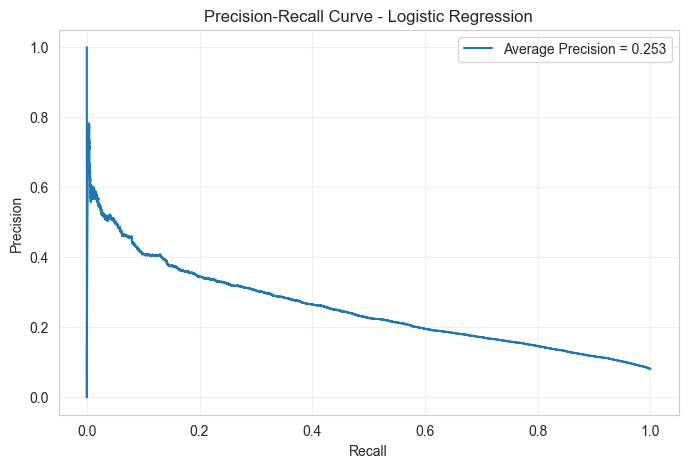

Average Precision: 0.2526


In [98]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

precision_values, recall_values, pr_thresholds = precision_recall_curve(
    y_test_final,
    final_y_prob
)

average_precision = average_precision_score(
    y_test_final,
    final_y_prob
)

plt.figure(figsize=(8, 5))
plt.plot(recall_values, precision_values, label=f"Average Precision = {average_precision:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Average Precision:", round(average_precision, 4))

In [99]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score

X_subtrain, X_validation, y_subtrain, y_validation = train_test_split(
    X_train_final_processed,
    y_train_final,
    test_size=0.20,
    stratify=y_train_final,
    random_state=42
)

validation_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

validation_model.fit(X_subtrain, y_subtrain)

validation_probabilities = validation_model.predict_proba(
    X_validation
)[:, 1]

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    predictions = (validation_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_validation, predictions, zero_division=0),
        "Recall": recall_score(y_validation, predictions, zero_division=0),
        "F1 Score": f1_score(y_validation, predictions, zero_division=0)
    })

validation_threshold_table = pd.DataFrame(threshold_results)

display(validation_threshold_table)

best_threshold = validation_threshold_table.loc[
    validation_threshold_table["F1 Score"].idxmax(),
    "Threshold"
]

print("Selected validation threshold:", best_threshold)

,Threshold,Precision,Recall,F1 Score
0,0.30,0.115295,0.897281,0.204334
1,0.35,0.127197,0.861782,0.221675
2,0.40,0.140074,0.814703,0.239049
3,0.45,0.154540,0.758812,0.256784
4,0.50,0.169114,0.692850,0.271870
5,0.55,0.187462,0.624119,0.288323
6,0.60,0.207533,0.549345,0.301256


Selected validation threshold: 0.6


In [100]:
from sklearn.metrics import classification_report, confusion_matrix

final_test_predictions = (
    final_y_prob >= best_threshold
).astype(int)

print("Final test evaluation at validation-selected threshold:")
print(classification_report(
    y_test_final,
    final_test_predictions,
    target_names=["Non-Defaulter", "Defaulter"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test_final, final_test_predictions))

Final test evaluation at validation-selected threshold:
               precision    recall  f1-score   support

Non-Defaulter       0.95      0.82      0.88     56538
    Defaulter       0.21      0.55      0.31      4965

     accuracy                           0.80     61503
    macro avg       0.58      0.69      0.60     61503
 weighted avg       0.89      0.80      0.84     61503

Confusion Matrix:
[[46437 10101]
 [ 2227  2738]]


In [101]:
risk_analysis = pd.DataFrame({
    "Actual_Default": y_test_final.values,
    "Predicted_Probability": final_y_prob
})

risk_analysis["Risk_Category"] = pd.cut(
    risk_analysis["Predicted_Probability"],
    bins=[-float("inf"), 0.30, 0.60, float("inf")],
    labels=["Low Risk", "Medium Risk", "High Risk"],
    right=False
)

risk_summary = risk_analysis.groupby(
    "Risk_Category",
    observed=False
).agg(
    Customer_Count=("Actual_Default", "count"),
    Actual_Defaulters=("Actual_Default", "sum"),
    Actual_Default_Rate=("Actual_Default", "mean")
).reset_index()

risk_summary["Actual_Default_Rate"] *= 100

display(risk_summary)

risk_summary.to_csv("customer_risk_segmentation.csv", index=False)

print("Customer risk segmentation saved successfully!")

,Risk_Category,Customer_Count,Actual_Defaulters,Actual_Default_Rate
0,Low Risk,22722,480,2.112490
1,Medium Risk,25942,1747,6.734253
2,High Risk,12839,2738,21.325648


Customer risk segmentation saved successfully!


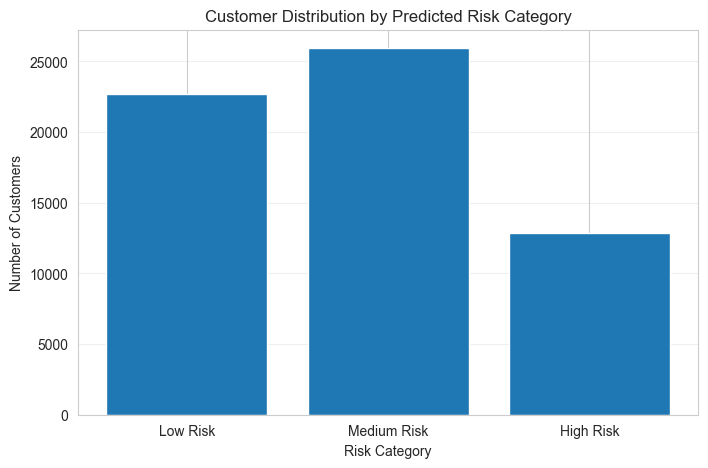

In [102]:
plt.figure(figsize=(8, 5))

plt.bar(
    risk_summary["Risk_Category"].astype(str),
    risk_summary["Customer_Count"]
)

plt.title("Customer Distribution by Predicted Risk Category")
plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")
plt.grid(axis="y", alpha=0.3)
plt.show()